# Welome to the Curve Tracer!

Below you'll find Maile Ruiz's Senior thesis. Its long and definetly not as streamlined as it could be, but it works, gosh darnit! If you have any questions, please email me at maileruiz1912@gmail.com

**The note book is laid out in two chapters:**

## Chapter 1: The backbones
You must run all of these cells before you can actually begin tracing! This section contains each of the functions that make the pipeline work as well as descriptions for how they work. If you just want to use the code, (for example, you have my templates that already work for a bunch of objects I've looked at) feel free to skip to Chapter 2, but when you run into bugs, it is helpful to refer to this section to understand how to code actually works. Refer to the comments in the actual functions for specifics on parameters, returns, and displays.
## Chapter 2: Trace the Curves
In this section, I've given a nice example of how to use the code. If you are efficent, you can complete the whole operation in only two cells of input code.

# Chapter 1: The Backbones

Here is where the magic happens. First you'll need to import all the packages needed for this pipeline of which there are many.

In [ ]:
    from astropy.io import fits
    import matplotlib.pyplot as plt
    import matplotlib.transforms as mtransforms
    import numpy as np
    from scipy.ndimage import rotate, shift
    from astropy.wcs import WCS
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from astropy.stats import sigma_clipped_stats
    from scipy.optimize import curve_fit, minimize
    from sklearn.linear_model import RANSACRegressor, LinearRegression
    import sklearn
    from matplotlib.transforms import Affine2D
    

**eval_trace**
Think of this function as the first examination of your fits file. When begining a new object, you'll want to play around with this function first to find a position angle that makes the object as verticle as possible (usually the position angle given by the literature) and minimum sigma value that traces the object well. You'll eventually use the image_data output later to make your tilted images.

Note that this verison of the code places a circular mask over the center of the image to prevent over tracing smeared out edges.

In [ ]:


def eval_trace(fits_file, positionAngle, ra, dec, minSig_factor=None):
    """
    Load in data, shift to center geine ra and dec, mask out four arcsecond radius circle, 
    rotate image according to evaluate. Display prelimnary traced region.
    
    Parameters:
        fits_file (fits_file): Your fits_file
        position angle (float): Position angle of object
        ra (sexadecimal sting): The right acension of the center of the object
        dec (sexadecimal sting): The declination of the center of the object
        minSig_factor (float): how many sigma above the noise do you wan to trace.

    Returns:
        image_data: Unrotated image with center masked out
        rotated_data: Image rotated by positionAngle with center masked out
        center_x: x coordinate of image and rotated center in pixels
        center_y: y coordinate of image and rotated center in pixels
        
    Displays:
        Rotated image with prelinary trace
    
    """
    # Open data
    with fits.open(fits_file) as hdulist:
        image_data = hdulist[0].data
        header = hdulist[0].header

    # WCS setup (so that we convert from right acension and declination to pixels)
    wcs_3d = WCS(header)
    wcs = wcs_3d.celestial  
    sky_coord = SkyCoord(ra, dec, frame='icrs')
    
    


    # Convert world to pixel and find center in pixels
    x_center, y_center = wcs.world_to_pixel(sky_coord)
    print("x_center:", x_center, "y_center:", y_center)
    

    

    #calculate noise from image then calculate three sigma above that
    mean, median, std = sigma_clipped_stats(image_data, sigma=3.0)
    minSig = std * minSig_factor

    
    # ---- Create circular mask in pixel units ----
    # Convert 4 arcseconds to pixels using pixel scale
    # Assume CD1_1 or CDELT1 gives degrees/pixel
    if 'CDELT1' in header:
        deg_per_pixel = np.abs(header['CDELT1'])  # degrees/pixel
    elif 'CD1_1' in header:
        deg_per_pixel = np.abs(header['CD1_1'])
    else:
        raise ValueError("WCS pixel scale not found in header.")

    arcsec_per_pixel = deg_per_pixel * 3600  # arcsec/pixel
    print(arcsec_per_pixel)
    radius_pixels = 4 / arcsec_per_pixel

    # Create circular mask
    Y, X = np.ogrid[:image_data.shape[0], :image_data.shape[1]]
    dist_from_center = np.sqrt((X - x_center)**2 + (Y - y_center)**2)
    mask = dist_from_center <= radius_pixels

    # Apply mask: set region to zero
    image_data = image_data.copy() 
    image_data[mask] = 0
    

    
    # Shift so that (x_center, y_center) is at the center of the image
    image_center = np.array(image_data.shape) / 2
    shift_to_center = image_center - np.array([y_center, x_center])  # (y, x) order for shift
    shifted = shift(image_data, shift=shift_to_center)

    # Rotate about the center of the image
    rotated_data = rotate(shifted, angle=positionAngle, reshape=True)

    # Since we shifted to center, rotated_data's new center still corresponds to original RA/Dec
    height, width = rotated_data.shape
    center_x = width // 2
    center_y = height // 2


    
    
    #---- Extract horizantal rows from left of center_x and right of center_x ----
    

    #-------------------------------
    
    # This will store all the left-half horizontal lines
    all_left_half_lines = []
    all_right_half_lines = []
    
    for y_coord in range(height):
        # Extract left half of the row
        horizontal_line_left = rotated_data[y_coord, :center_x]
        all_left_half_lines.append(horizontal_line_left)
        
    
    for y_coord in range(height):
        # Extract right half of the row
        horizontal_line_right = rotated_data[y_coord, center_x:]
        all_right_half_lines.append(horizontal_line_right)
    

    #these will store the crossing postions x and y for the left and right sides
    x_crossings_left = []
    y_crossings_left = []
    x_crossings_right = []
    y_crossings_right = []
    
    #these will store the crossings to be fit to (flips the left side over to the right side so that they're overlaid)
    x_crossings=[]
    y_crossings=[]
    

    # -----Extract left-hand crossings-----
    
    for y_coord, line in enumerate(all_left_half_lines):

        
        line_len = len(line)
        
        x_start = 0
        x_end = line_len
        sliced_line = line[x_start:x_end]

        # Find crossings
        crossings = np.where(np.diff(np.sign(sliced_line - minSig)) != 0)[0]
        if len(crossings) > 0:
            idx = crossings[0]
            x0, x1 = idx, idx + 1
            y0, y1 = sliced_line[x0], sliced_line[x1]
            slope = y1 - y0
            x_cross = x0 if slope == 0 else x0 + (minSig - y0) / slope
            x_cross += x_start  # offset due to slicing
            
            x_crossings_left.append(x_cross)
            y_crossings_left.append(y_coord)
            
            x_crossings.append(-x_cross+2*center_x)
            y_crossings.append(y_coord)

    # -----Extract right-hand crossings----
    
    for y_coord, line in enumerate(all_right_half_lines):
    
        line_len = len(line)
        x_start = 0
        x_end= line_len
        sliced_line = line[x_start:x_end]

        crossings = np.where(np.diff(np.sign(sliced_line - minSig)) != 0)[0]
        if len(crossings) > 0:
            idx = crossings[-1]  # last crossing
            x0, x1 = idx, idx + 1
            y0, y1 = sliced_line[x0], sliced_line[x1]
            slope = y1 - y0
            x_cross = x0 if slope == 0 else x0 + (minSig - y0) / slope
            x_cross += x_start  # offset due to slicing
            
            x_crossings_right.append(center_x + x_cross)
            y_crossings_right.append(y_coord)

            x_crossings.append(center_x + x_cross)
            y_crossings.append(y_coord)
            
    
    #----Plot Rotated Data with Preliminary tracings----
    plt.figure(figsize=(6, 6))
    plt.imshow(rotated_data, cmap='gray', origin='lower')

    plt.axvline(x=center_x, color='white', linestyle='--', linewidth=1, label='Vertical Center')
    plt.axhline(y=center_y, color='cyan', linestyle='--', linewidth=1, label='Horizontal Center')
    # Plot points on top of the image
    plt.scatter(x_crossings_left, y_crossings_left, color='deeppink', s=4, marker='o', label='Traced Outflow (Left)')
    plt.scatter(x_crossings_right, y_crossings_right, color='darkviolet', s=4, marker='o', label='Traced Outflow (Right)')

    #plt.legend()
    plt.ylabel('x (pixels)', fontsize=20)
    plt.xlabel('y (pixels)', fontsize=20)
    #plt.title(f'Per-emb 5 (Blue-shifted) with Preliminary Tracings')
    plt.legend()
    plt.show()

    
    return image_data, rotated_data, center_x, center_y

**mask_trace** You may have noticed that you can't always get a perfect tracing with evaltrace alone. In that case, you can mask out certain rectangular sections of your fits. This code relies on a delicate balance of adjusting the sigma value, masks, and detecting statistical outliers (in a later step) to ensure an accurate tracing and power law fitting.

This function is somewhat of a relic, but can still be used to gage out the masks youll need to apply. The actual masks used for the function are applied in **tilt_data**

The rectangular bounds are described in the function below.

In [ ]:


def mask_trace(fits_file, positionAngle, ra, dec, minSig_factor, min_x=None, max_x=None,
                   min_y_left=None, max_y_left=None, min_y_right=None, max_y_right=None):
    """
    Mask out everything outside of two specified rectangles (one for left side and one for right side) 
    and perform new trace
    
    Parameters:
        fits_file (fits_file): Your fits_file
        position angle (float): Position angle of object
        ra (sexadecimal sting): The right acension of the center of the object
        dec (sexadecimal sting): The declination of the center of the object
        minSig_factor (float): how many sigma above the noise do you wan to trace.
        
        min_x (int, optional): Minimum x index for left-hand rectangle
        max_x (int, optional): Maximum x index for right-hand rectangle
        min_y_left (int, optional): Minimum y index for left-hand rectangle
        max_y_left (int, optional): Maximum y index for left-hand rectangle
        min_y_right (int, optional): Minimum y index for right-hand rectangle
        max_y_right (int, optional): Maximum y index for rught-hand rectangle
        
    Displays:
        Masked out data and trace according to mask
    """
    # Open data
    with fits.open(fits_file) as hdulist:
        image_data = hdulist[0].data
        header = hdulist[0].header

    # WCS setup
    wcs_3d = WCS(header)
    wcs = wcs_3d.celestial  
    sky_coord = SkyCoord(ra, dec, frame='icrs')

    # Convert world to pixel
    x_center, y_center = wcs.world_to_pixel(sky_coord)
    print("x_center:", x_center, "y_center:", y_center)

    # ---- Create circular mask in pixel units ----
    # Convert 4 arcseconds to pixels using pixel scale
    # Assume CD1_1 or CDELT1 gives degrees/pixel
    if 'CDELT1' in header:
        deg_per_pixel = np.abs(header['CDELT1'])  # degrees/pixel
    elif 'CD1_1' in header:
        deg_per_pixel = np.abs(header['CD1_1'])
    else:
        raise ValueError("WCS pixel scale not found in header.")

    arcsec_per_pixel = deg_per_pixel * 3600  # arcsec/pixel
    radius_pixels = 4 / arcsec_per_pixel

    # Create circular mask
    Y, X = np.ogrid[:image_data.shape[0], :image_data.shape[1]]
    dist_from_center = np.sqrt((X - x_center)**2 + (Y - y_center)**2)
    mask = dist_from_center <= radius_pixels

    # Apply mask: set region to zero
    image_data = image_data.copy()  # avoid modifying in-place
    image_data[mask] = 0
    
    
  

    # ---- Rotate around custom center ----
    custom_center = (x_center, y_center)
    image_center = np.array(image_data.shape) / 2
    shift_to_center = image_center - custom_center
    shifted = shift(image_data, shift=shift_to_center)
    rotated_data = rotate(shifted, angle=positionAngle, reshape=True)

    # Find new image center
    height, width = rotated_data.shape
    center_x = width // 2
    center_y = height // 2
    
    rect1 = (min_x, center_x, min_y_left, max_y_left)  # example values, update to your desired rectangle
    rect2 = (center_x, max_x, min_y_right, max_y_right)

    # Create a mask that starts as all False
    mask = np.zeros_like(rotated_data, dtype=bool)

    # Set True in regions inside the rectangles
    mask[rect1[2]:rect1[3], rect1[0]:rect1[1]] = True
    mask[rect2[2]:rect2[3], rect2[0]:rect2[1]] = True

    # Apply the mask: everything outside the rectangles is set to 0
    masked_data = np.where(mask, rotated_data, -5)

    # Display masked out data
    plt.imshow(masked_data, cmap='gray', origin='lower')
    plt.colorbar()
    plt.title('Masked Image with Two Rectangular Regions')
    plt.show()
    
    
    #________ADDING Extraction
    
        #calculate center of image to divide left and right sides
    height, width = masked_data.shape
    center_x = width // 2  # Vertical center
    

    #-------------------------------
    
    # This will store all the left-half horizontal lines
    all_left_half_lines = []
    all_right_half_lines = []
    
    for y_coord in range(height):
        # Extract left half of the row
        horizontal_line_left = masked_data[y_coord, :center_x]
        all_left_half_lines.append(horizontal_line_left)
        
    
    for y_coord in range(height):
        # Extract right half of the row
        horizontal_line_right = masked_data[y_coord, center_x:]
        all_right_half_lines.append(horizontal_line_right)
    


    """CODE FOR FIND CROSSINGS"""
    
    mean, median, std = sigma_clipped_stats(image_data, sigma=3.0)
    minSig = std * minSig_factor

    x_crossings_left = []
    y_crossings_left = []
    x_crossings_right = []
    y_crossings_right = []
    
    x_crossings=[]
    y_crossings=[]

    # -------------------
    # left
    for y_coord, line in enumerate(all_left_half_lines):

        # Slice line by x bounds if provided
        line_len = len(line)
        #x_start = max(0, min_x) if min_x is not None else 0
        x_start = 0
        x_end = line_len
        sliced_line = line[x_start:x_end]

        # Find crossings
        crossings = np.where(np.diff(np.sign(sliced_line - minSig)) != 0)[0]
        if len(crossings) > 0:
            idx = crossings[0]
            x0, x1 = idx, idx + 1
            y0, y1 = sliced_line[x0], sliced_line[x1]
            slope = y1 - y0
            x_cross = x0 if slope == 0 else x0 + (minSig - y0) / slope
            x_cross += x_start  # offset due to slicing
            
            x_crossings_left.append(x_cross)
            y_crossings_left.append(y_coord)
            
            x_crossings.append(-x_cross+2*center_x)
            y_crossings.append(y_coord)

    # -------------------
    # right
    for y_coord, line in enumerate(all_right_half_lines):
    
        line_len = len(line)
        x_start = 0
        #x_end = min(line_len, max_x-center_x) if max_x is not None else line_len
        x_end= line_len
        sliced_line = line[x_start:x_end]

        crossings = np.where(np.diff(np.sign(sliced_line - minSig)) != 0)[0]
        if len(crossings) > 0:
            idx = crossings[-1]  # last crossing
            x0, x1 = idx, idx + 1
            y0, y1 = sliced_line[x0], sliced_line[x1]
            slope = y1 - y0
            x_cross = x0 if slope == 0 else x0 + (minSig - y0) / slope
            x_cross += x_start  # offset due to slicing
            
            x_crossings_right.append(center_x + x_cross)
            y_crossings_right.append(y_coord)

            x_crossings.append(center_x + x_cross)
            y_crossings.append(y_coord)
            
    #Display new tracings        
    plt.imshow(rotated_data, cmap='gray', origin='lower')
    plt.colorbar()

    # Example coordinates of points to plot
    plt.axvline(x=center_x, color='white', linestyle='--', linewidth=1, label='Vertical Center')
    plt.axhline(y=center_y, color='cyan', linestyle='--', linewidth=1, label='Horizontal Center')
    # Plot points on top of the image
    plt.scatter(x_crossings_left, y_crossings_left, color='deeppink', s=4, marker='o', label='Left hand')
    plt.scatter(x_crossings_right, y_crossings_right, color='darkviolet', s=4, marker='o', label='Right hand')

    #plt.legend()
    plt.title('Outflow from Masks Traced on Image')
    plt.show()
    
    


**tilt_data** To be a little more statistacally robust, we've created this function to create images at multiple postion angles so that the best postion angle may be statistically determined. For this function, you want to put in a postion angle that makes the object look about vertical (usually the position angle given by the literature).Then you'll indicate how many other tilted images you want to create using poistion angles above and below the given position angle.

Here, you'll re-input the masks you may have determined earlier with **mask_trace**.

*BEST PRACTICE TIP:* If you best position angle given by **combine_red_blue_tracings** is the first or last tilted image created, return to this step and expand the number of tilted images created until that is not the case.

In [ ]:


def tilt_data(fits_file, positionAngle, ra, dec,
              image_number=1, step_size=1,
              min_x=None, max_x=None,
              min_y_left=None, max_y_left=None,
              min_y_right=None, max_y_right=None):
    """
    Makes a list of tilted and masked images based on the inputs given, each image comes with
    the position angle it was rotated by.
    
    
    Parameters:
        fits_file (fits_file): Your fits_file
        position angle (float): Position angle of object
        ra (sexadecimal sting): The right acension of the center of the object
        dec (sexadecimal sting): The declination of the center of the object
        minSig_factor (float): How many sigma above the noise do you want to trace.
        
        image_number (int): How many tilted images you want (centered around given positionAngle)
        step_size (float): How many degrees apart you want each tilted image to be

        min_x (int, optional): Minimum x index for left-hand rectangle
        max_x (int, optional): Maximum x index for right-hand rectangle
        min_y_left (int, optional): Minimum y index for left-hand rectangle
        max_y_left (int, optional): Maximum y index for left-hand rectangle
        min_y_right (int, optional): Minimum y index for right-hand rectangle
        max_y_right (int, optional): Maximum y index for rught-hand rectangle
        
    Returns:
        List of tuples: (angle, image)

    
    
    """
    
    # --- Load Data ---
    with fits.open(fits_file) as hdulist:
        image_data = hdulist[0].data
        header = hdulist[0].header

    wcs_3d = WCS(header)
    wcs = wcs_3d.celestial  
    sky_coord = SkyCoord(ra, dec, frame='icrs')
    x_center, y_center = wcs.world_to_pixel(sky_coord)
    
    image_data_unmasked=image_data.copy()

    # --- Mask 4 arcsecond circle ---
    if 'CDELT1' in header:
        deg_per_pixel = np.abs(header['CDELT1'])
    elif 'CD1_1' in header:
        deg_per_pixel = np.abs(header['CD1_1'])
    else:
        raise ValueError("No valid pixel scale found in FITS header.")

    arcsec_per_pixel = deg_per_pixel * 3600
    radius_pixels = 4 / arcsec_per_pixel

    Y, X = np.ogrid[:image_data.shape[0], :image_data.shape[1]]
    dist_from_center = np.sqrt((X - x_center)**2 + (Y - y_center)**2)
    mask_circle = dist_from_center <= radius_pixels

    image_data = image_data.copy()
    image_data[mask_circle] = 0

    # --- Initial Rotation to Align Position Angle ---
    
    # Shift so that (x_center, y_center) is at the center of the image
    image_center = np.array(image_data.shape) / 2
    shift_to_center = image_center - np.array([y_center, x_center])  # (y, x) order for shift
    shifted = shift(image_data, shift=shift_to_center)
    shifted_unmasked = shift(image_data_unmasked, shift=shift_to_center)

    # Rotate about the center of the image
    rotated_data = rotate(shifted, angle=positionAngle, reshape=True)
    rotated_data_unmasked = rotate(shifted_unmasked, angle=positionAngle, reshape=True)

    # Since we shifted to center, rotated_data's new center still corresponds to original RA/Dec
    height, width = rotated_data.shape
    center_x = width // 2
    center_y = height // 2

    # --- Apply Rectangular Mask on Rotated Image ---
    height, width = rotated_data.shape
    center_x = width // 2
    center_y = height // 2

    rect1 = (min_x, center_x, min_y_left, max_y_left)
    rect2 = (center_x, max_x, min_y_right, max_y_right)

    mask_rects = np.zeros_like(rotated_data, dtype=bool)
    mask_rects[rect1[2]:rect1[3], rect1[0]:rect1[1]] = True
    mask_rects[rect2[2]:rect2[3], rect2[0]:rect2[1]] = True

    masked_data = np.where(mask_rects, rotated_data, -3)

    # --- Generate Tilted Versions ---
    angle_list = []
    angle_start = positionAngle - (image_number // 2) * step_size

    for i in range(image_number):
        angle = angle_start + i * step_size
        tilted_masked = rotate(masked_data, angle=(angle - positionAngle), reshape=False)
        tilted_unmasked = rotate(rotated_data_unmasked, angle=(angle - positionAngle), reshape=False)
        angle_list.append((angle, tilted_masked, tilted_unmasked))

    return angle_list  # list of (angle, image)


**mask_trace_all** This function uses the tilted images from tilt_data to actually trace the curves for each tilted image. There is an additional layer of rejecting traced pixel position. This can help with postions that are wrongly traced at the edge of a mask. Best to just play around with this one to get a feel for how it works.

In [ ]:
from astropy.stats import sigma_clipped_stats
import numpy as np
import matplotlib.pyplot as plt

def mask_trace_all(tilted_images, original_image, minSig_factor, crossing_scope=10, crossing_threshold=0.8):
    """
    Loop over rotated/masked images and trace the outflow crossings on each,
    displaying the traced boundaries.

    Parameters
    ----------
    tilted_images : list of tuples
        List containing the rotated/masked image data. Each element should be a tuple:
        (angle, masked_data, unmasked_data)
        where:
            angle : float
                Rotation angle of the image in degrees.
            masked_data : 2D numpy.ndarray
                The masked/processed image used for detecting outflow crossings.
            unmasked_data : 2D numpy.ndarray
                The original rotated image before masking.

    original_image : 2D numpy.ndarray
        The original unrotated image used to calculate the noise level.
        Sigma-clipped statistics are computed from this image to determine
        the detection threshold.

    minSig_factor : float
        Multiplicative factor applied to the image standard deviation to define
        the minimum signal threshold:
        
            minSig = std * minSig_factor
        
        Crossings are identified where the image intensity crosses this threshold.

    crossing_scope : int, optional
        Number of pixels on either side of a detected crossing used to evaluate
        whether the crossing is a valid outflow edge. Larger values examine a
        wider neighborhood around the crossing.
        Default is 10.

    crossing_threshold : float, optional
        Fraction of pixels within the crossing_scope region that must satisfy
        the rejection condition for a crossing to be discarded. Used to remove
        false detections caused by negative regions/noise.
        Default is 0.8.

    Returns
    -------
    results : list of tuples
        List containing the traced crossing information for each tilted image.
        Each tuple contains:
        
            masked_data : 2D numpy.ndarray
                The masked image associated with the trace.

            x_crossings : list
                X pixel coordinates of detected outflow edge crossings.

            y_crossings : list
                Y pixel coordinates of detected outflow edge crossings.

            angle : float
                Rotation angle corresponding to the traced image.
    """

    results = []

    # Compute global image stats once
    mean, median, std = sigma_clipped_stats(original_image, sigma=3.0)
    minSig = std * minSig_factor

    num_images = len(tilted_images)
    cols = 3
    rows = int(np.ceil(num_images / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 5))
    axes = axes.flatten()

    for i, (angle, masked_data, unmasked_data) in enumerate(tilted_images):
        height, width = masked_data.shape
        center_x = width // 2
        center_y = height // 2

        x_crossings_left = []
        y_crossings_left = []
        x_crossings_right = []
        y_crossings_right = []
        x_crossings = []
        y_crossings = []

        for y_coord in range(height):
            line = masked_data[y_coord]
            left_half = line[:center_x]
            right_half = line[center_x:]

            # --- Left ---
            crossings = np.where(np.diff(np.sign(left_half - minSig)) != 0)[0]
            if len(crossings) > 0:
                idx = crossings[0]
                before = left_half[max(0, idx - crossing_scope):idx]
                after = left_half[idx + 1:idx + crossing_scope + 1]
                if (
                    (len(before) > 0 and np.count_nonzero(before < -.5) / len(before) > crossing_threshold) or
                    (len(after) > 0 and np.count_nonzero(after < -.5) / len(after) > crossing_threshold)
                ):
                    continue

                x0, x1 = idx, idx + 1
                y0, y1 = left_half[x0], left_half[x1]
                slope = y1 - y0
                x_cross = x0 if slope == 0 else x0 + (minSig - y0) / slope

                x_crossings_left.append(x_cross)
                y_crossings_left.append(y_coord)
                x_crossings.append(-x_cross + 2 * center_x)
                y_crossings.append(y_coord)

            # --- Right ---
            crossings = np.where(np.diff(np.sign(right_half - minSig)) != 0)[0]
            if len(crossings) > 0:
                idx = crossings[-1]
                before = right_half[max(0, idx - crossing_scope):idx]
                after = right_half[idx + 1:idx + crossing_scope + 1]
                if (
                    (len(before) > 0 and np.count_nonzero(before < -.5) / len(before) > crossing_threshold) or
                    (len(after) > 0 and np.count_nonzero(after < -.5) / len(after) > crossing_threshold)
                ):
                    continue

                x0, x1 = idx, idx + 1
                y0, y1 = right_half[x0], right_half[x1]
                slope = y1 - y0
                x_cross = x0 if slope == 0 else x0 + (minSig - y0) / slope

                x_crossings_right.append(center_x + x_cross)
                y_crossings_right.append(y_coord)
                x_crossings.append(center_x + x_cross)
                y_crossings.append(y_coord)

        # --- Plot in grid ---
        ax = axes[i]
        im = ax.imshow(masked_data, cmap='gray', origin='lower')
        ax.axvline(x=center_x, color='white', linestyle='--', linewidth=1)
        ax.axhline(y=center_y, color='cyan', linestyle='--', linewidth=1)
        ax.scatter(x_crossings_left, y_crossings_left, color='deeppink', s=4, label='Left')
        ax.scatter(x_crossings_right, y_crossings_right, color='darkviolet', s=4, label='Right')
        ax.set_title(f'{angle:.1f}° Tilt')
        ax.axis('off')

        results.append((masked_data, x_crossings, y_crossings, angle))

    # Turn off any unused axes
    for j in range(len(tilted_images), len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

    return results

**image_stats** This function return essential stats that the pipeline must use to run properly

In [ ]:
def image_stats(red_fits=None, blue_fits=None, ra=None, dec=None):
    """
    Aligns two FITS images on the same RA/Dec center and returns
    normalized red and blue images ready for contour plotting.
    
    """
    

    # --- Load + align red ---
    with fits.open(red_fits) as hdul:
        r = hdul[0].data
        wcs_r = WCS(hdul[0].header).celestial

    coord = SkyCoord(ra, dec)
    xr, yr = wcs_r.world_to_pixel(coord)
    
    print("red x y:", xr, yr)

    shift_r = np.array(r.shape)/2 - np.array([yr, xr])
    r_shift = shift(r, shift_r)
    
    mean_r, median_r, std_r = sigma_clipped_stats(r, sigma=3)

    # --- Load + align blue ---
    with fits.open(blue_fits) as hdul:
        b = hdul[0].data
        wcs_b = WCS(hdul[0].header).celestial

    xb, yb = wcs_b.world_to_pixel(coord)
    print("blue x y:", xb, yb)
    shift_b = np.array(b.shape)/2 - np.array([yb, xb])
    b_shift = shift(b, shift_b)
    
    mean_b, median_b, std_b = sigma_clipped_stats(b, sigma=3)

    
    r_peak = np.max(r)
    b_peak = np.max(b)

    return (r_shift, b_shift, std_r, std_b, r_peak, b_peak, xr, yr, xb, yb)

**save_plot_data** While not essential to actually running the code, this function saves the finshed results into a pickle file which can be easily used late to plot in matplotlib

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.transforms import Affine2D
import numpy as np
import pickle
import glob
import os


def save_plot_data(source_name, center_y, xr, yr, xb, yb, best_angle_r, best_angle_b, 
                   image_r, levels_r, x_curve_r, y_curve_r, 
                   image_b, levels_b, x_curve_b, y_curve_b, 
                   m_b, p_b, method, pixscale=0.4000000246236,
                   include_red=True, include_blue=True):
    
    data_to_save = {
        'source_name': source_name,
        'center_y': center_y, 'xr': xr, 'yr': yr, 'xb': xb, 'yb': yb,
        'best_angle_r': best_angle_r, 'best_angle_b': best_angle_b,
        'image_r': image_r, 'levels_r': levels_r, 
        'x_curve_r': x_curve_r, 'y_curve_r': y_curve_r,
        'image_b': image_b, 'levels_b': levels_b, 
        'x_curve_b': x_curve_b, 'y_curve_b': y_curve_b,
        'm_b': m_b, 'p_b': p_b,
        'method': method,
        'pixscale': pixscale,
        'include_red': include_red,
        'include_blue': include_blue
    }
    
    # Save to a pickle file
    filename = f"{source_name.replace(' ', '_')}_plotdata.pkl"
    with open(filename, 'wb') as f:
        pickle.dump(data_to_save, f)
    print(f"Saved plot data to {filename}")



**combine_red_blue_tracings** This hefty function is the meat and potatoes of the whole pipeline. It fits powerlaws to each of the tilted and traced images you created before and returns the the best fit postion angle and powerlaw for but the the redshifted and blueshifted side of your object. But, the parameters are fairly simple!

In [ ]:
def combine_red_blue_tracings(red=None, blue=None, center_y=None, plot=True, red_ims=None, blue_ims=None, image_stats=None, blue_threshold=0.8, red_threshold=0.8, name=None, include_red=True, include_blue=True):
    """
    Combine red and blue traced results by angle, with optional removal of point regions.

    Parameters:
        red (list): List of (image, x_crossings, y_crossings, angle) for red side.
        blue (list): List of (image, x_crossings, y_crossings, angle) for blue side.
        center_y (float): The vertical center to reflect red side y-values.
        plot (bool): Whether to generate scatter plots for each combined result.
        red_ims: Your return for the red side of mask_trace_all
        blue_ims: Your return for the blue side of mask_trace_all
        image_stats: Your return from image_stats
        
        blue_threshold : float, optional
            Minimum fraction of RANSAC inlier points required for a blue-shifted
            fit to be considered valid when selecting the best angle.
            Default is 0.8.

        red_threshold : float, optional
            Minimum fraction of RANSAC inlier points required for a red-shifted
            fit to be considered valid when selecting the best angle.
            Default is 0.8.


    Returns:
        combined_results (list): List of (img_r, img_b, combined_x, combined_y, angle)
        
        
    """
    
    #image_stats (for contours and final image)
    red_img, blue_img, std_r, std_b, r_peak, b_peak, xr, yr, xb, yb= image_stats
    levels_r = np.arange(3*std_r, r_peak, 4*std_r)
    levels_b = np.arange(3*std_b, b_peak, 4*std_b)


    
    if red is not None:
        red_dict = {float(angle): (img, x, y) for img, x, y, angle in red}
        image_dict_r = {round(float(a), 3): (masked_img, img) for a, masked_img, img in red_ims} if red_ims else {}
    else:
        red_dict = None
        print("No Red Data Given")
        
    if blue is not None:   
        blue_dict = {float(angle): (img, x, y) for img, x, y, angle in blue}
        image_dict_b = {round(float(a), 3): (masked_img, img) for a, masked_img, img in blue_ims} if red_ims else {}
    else:
        blue_dict = None
        print("No Blue Data Given")
    
    chi2_results_log_red = []
    chi2_results_log_blue = []
    if include_red is True:
        if red is not None:
            for i, angle in enumerate(red_dict):
                img_r, x_r, y_r = red_dict[angle]
                label = f"{angle:.1f}°"
                print(f"\033[1m{label}: Redshifted Data\033[0m")

                #check if red or blue is on top
                check_neg=np.array([(center_y - y) for y in y_r])

                fraction_negative = np.mean(check_neg < 0)  # gives the proportion of elements < 0

                if fraction_negative > 0.5:
                    method="redtop"
                else:
                    method="bluetop"

                 #_____CALCULATE RED IN CASE OF REDTOP_____
                if method == "redtop":

                    #proceed after you know if red or blue is on top
                    y_r_reflected = np.array(y_r)-center_y#np.array([(center_y - y) for y in y_r])
                    x_r=np.array(x_r)-center_y

                    # Keep only positive, finite values (required for log)
                    valid_mask = (x_r > 0) & (y_r_reflected > 0) & np.isfinite(x_r) & np.isfinite(y_r_reflected)

                    x_r = x_r[valid_mask]
                    y_r_reflected = y_r_reflected[valid_mask]

                    #logged data
                    logx_r = np.log10(x_r).reshape(-1, 1)
                    logy_r_reflected = np.log10(y_r_reflected)

                    '''# Compute z-scores for logx_r
                    z_scores = np.abs((logx_r - np.mean(logx_r)) / np.std(logx_r))
                    # Create a mask for points within 3 standard deviations (you can adjust 3 → 2.5 or 2)
                    mask = z_scores < 3
                    mask = mask.flatten()  # or mask.ravel()
                    # Apply mask to both arrays
                    logx_r = logx_r[mask]
                    logy_r_reflected = logy_r_reflected[mask]'''




                    z_scores = np.abs((logx_r - np.mean(logx_r)) / np.std(logx_r))
                    z_mask = (z_scores < 3).ravel()
                    print(f"Removed {np.sum(~z_mask)} outliers.")
                    print(f"Remaining points: {len(logx_r)}")

                    logx_r = logx_r[z_mask]
                    logy_r_reflected = logy_r_reflected[z_mask]

                    print(f"Removed {np.sum(~z_mask)} outliers.")
                    print(f"Remaining points: {len(logx_r)}")





                    # Define the base linear model
                    base_model = LinearRegression()

                    # Fit RANSAC
                    ransac = RANSACRegressor(base_model, 
                                     min_samples=len(logx_r), 
                                     residual_threshold=None, 
                                     random_state=1)

                    #print(logy_r_reflected)

                    ransac.fit(logx_r, logy_r_reflected)

                    # Extract slope (p) and intercept (log m)
                    p_ransac = ransac.estimator_.coef_[0]
                    logm_ransac = ransac.estimator_.intercept_
                    m_ransac = 10 ** logm_ransac

                    print(f"RANSAC estimated exponent p = {p_ransac:.3f}")
                    print(f"RANSAC estimated prefactor m = {m_ransac:.3f}")

                    #curve in linear space
                    x_curve = np.linspace(min(x_r), max(x_r), 200)
                    y_curve = m_ransac * (x_curve)**p_ransac # power-law in regular space


                    #Chi-square calculation
                    inlier_mask = ransac.inlier_mask_
                    outlier_mask = np.logical_not(inlier_mask)

                    # --- Compute reduced chi-squared in log space ---
                    logy_pred = ransac.predict(logx_r[inlier_mask])

                    # Residuals in log space
                    residuals_log = logy_r_reflected[inlier_mask] - logy_pred

                    # You can assume uniform errors (σ = std of residuals) if no uncertainties provided
                    sigma_log = np.std(residuals_log)
                    chi_squared_log = np.sum(residuals_log** 2)
                    dof_log = len(logx_r[inlier_mask]) - 2  # 2 parameters: slope and intercept
                    reduced_chi_squared_log = chi_squared_log / dof_log if dof_log > 0 else np.nan


                    inlier_fraction = np.sum(inlier_mask) / len(inlier_mask)

                   # chi2_results_log_red.append((angle, reduced_chi_squared_log,x_curve, y_curve, inlier_fraction))

                    chi2_results_log_red.append((angle, reduced_chi_squared_log,x_curve, y_curve, m_ransac, p_ransac, inlier_fraction))


                    print(f"→ Reduced χ² (log space) for {label}: {reduced_chi_squared_log:.3f}")



                    if plot:


                        #plot
                        plt.figure(figsize=(10, 4))
                        plt.subplot(1, 2, 1)
                        plt.scatter(logx_r[inlier_mask], logy_r_reflected[inlier_mask], color='red', label='Inliers')
                        plt.scatter(logx_r[outlier_mask], logy_r_reflected[outlier_mask], color='darkgrey', marker='s', label='Outliers')
                        plt.plot(logx_r, ransac.predict(logx_r), color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        #plt.title(f'Ransac fit in log space ({label})')
                        plt.xlabel("log(x) (Pixels)", fontsize=20)
                        plt.ylabel("log(y) (Pixels)", fontsize=20)
                        #plt.grid(True)
                        plt.legend()



                        #plot fit in linear space
                        plt.subplot(1, 2, 2)
                        plt.scatter(10**logx_r[inlier_mask], 10**logy_r_reflected[inlier_mask], color='red', label='Inliers')
                        plt.scatter(10**logx_r[outlier_mask], 10**logy_r_reflected[outlier_mask], color='darkgrey', marker='s', label='Outliers')
                        plt.plot(x_curve, y_curve, color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        #plt.title(f'Ransac fit in linear space ({label})')
                        plt.xlabel("x (Pixels)", fontsize=20)
                        plt.ylabel("y (Pixels)", fontsize=20)
                        plt.legend()
                        #plt.grid(True)
                        plt.tight_layout()
                        plt.show()

                        #plot fits on image
                        plt.figure(figsize=(4,4))
                        image = image_dict_r.get(round(float(angle), 3), (None, None))[1]
                        plt.contour(image, levels=levels_r, colors='red')
                        plt.plot(x_curve+center_y, y_curve+center_y, color='black', alpha=1, linewidth=2)
                        plt.plot(-x_curve+center_y, y_curve+center_y, color='black', alpha=1,  linewidth=2)
                        plt.show()

                #_____CALCULATE RED IN CASE OF BLUETOP_____
                if method == "bluetop":
                    #linear data
                    y_r_reflected = np.array([(center_y - y) for y in y_r])
                    x_r=np.array(x_r)-center_y


                    # NEW: filter invalid values BEFORE log
                    valid_mask = (
                        (x_r > 0) &
                        (y_r_reflected > 0) &
                        np.isfinite(x_r) &
                        np.isfinite(y_r_reflected)
                    )

                    x_r = x_r[valid_mask]
                    y_r_reflected = y_r_reflected[valid_mask]
                    # -------------------------------

                    # Logged data (now safe)
                    logx_r = np.log10(x_r).reshape(-1, 1)
                    logy_r_reflected = np.log10(y_r_reflected)

                    # Z-score filtering
                    z_scores = np.abs((logx_r - np.mean(logx_r)) / np.std(logx_r))
                    z_mask = (z_scores < 3).ravel()

                    logx_r = logx_r[z_mask]
                    logy_r_reflected = logy_r_reflected[z_mask]
                    print(f"Removed {np.sum(~z_mask)} outliers.")
                    print(f"Remaining points: {len(logx_r)}")


                    # Define the base linear model
                    base_model = LinearRegression()

                    # Fit RANSAC
                    ransac = RANSACRegressor(base_model, 
                                     min_samples=len(logx_r), 
                                     residual_threshold=None, 
                                     random_state=1)

                    ransac.fit(logx_r, logy_r_reflected)

                    # Extract slope (p) and intercept (log m)
                    p_ransac = ransac.estimator_.coef_[0]
                    logm_ransac = ransac.estimator_.intercept_
                    m_ransac = 10 ** logm_ransac

                    print(f"RANSAC estimated exponent p = {p_ransac:.3f}")
                    print(f"RANSAC estimated prefactor m = {m_ransac:.3f}")

                    #curve in linear space
                    x_curve = np.linspace(min(x_r), max(x_r), 200)
                    y_curve = m_ransac * (x_curve)**p_ransac # power-law in regular space


                    #Chi-square calculation
                    inlier_mask = ransac.inlier_mask_
                    outlier_mask = np.logical_not(inlier_mask)

                    # --- Compute reduced chi-squared in log space ---
                    logy_pred = ransac.predict(logx_r[inlier_mask])

                    # Residuals in log space
                    residuals_log = logy_r_reflected[inlier_mask] - logy_pred

                    # You can assume uniform errors (σ = std of residuals) if no uncertainties provided
                    sigma_log = np.std(residuals_log)
                    chi_squared_log = np.sum(residuals_log** 2)
                    dof_log = len(logx_r[inlier_mask]) - 2  # 2 parameters: slope and intercept
                    reduced_chi_squared_log = chi_squared_log / dof_log if dof_log > 0 else np.nan

                    #chi2_results_log_red.append((angle, reduced_chi_squared_log,x_curve, y_curve, m_ransac, p_ransac))
                    inlier_fraction = np.sum(inlier_mask) / len(inlier_mask)

                    chi2_results_log_red.append((angle, reduced_chi_squared_log,x_curve, y_curve, m_ransac, p_ransac, inlier_fraction))


                    print(f"→ Reduced χ² (log space) for {label}: {reduced_chi_squared_log:.3f}")



                    if plot:


                        #plot
                        plt.figure(figsize=(10, 4))
                        plt.subplot(1, 2, 1)
                        plt.scatter(logx_r[inlier_mask], logy_r_reflected[inlier_mask], color='red', label='Inliers')
                        plt.scatter(logx_r[outlier_mask], logy_r_reflected[outlier_mask], color='darkgrey', marker='s', label='Outliers')
                        plt.plot(logx_r, ransac.predict(logx_r), color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        #plt.title(f'Ransac fit in log space ({label})')
                        plt.xlabel("log(x) (Pixels)", fontsize=15)
                        plt.ylabel("log(y) (Pixels)", fontsize=15)

                        #plt.grid(True)
                        plt.legend()



                        #plot fit in linear space
                        plt.subplot(1, 2, 2)
                        plt.scatter(10**logx_r[inlier_mask], 10**logy_r_reflected[inlier_mask], color='red', label='Inliers')
                        plt.scatter(10**logx_r[outlier_mask], 10**logy_r_reflected[outlier_mask], color='darkgrey', marker='s', label='Outliers')
                        plt.plot(x_curve, y_curve, color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        #plt.title(f'Ransac fit in linear space ({label})')
                        plt.xlabel("x (Pixels)", fontsize=15)
                        plt.ylabel("y (Pixels)", fontsize=15)
                        plt.legend()

                        #plt.grid(True)
                        #plt.tight_layout()
                        plt.show()








                        #HERE HERE HERE
                        pixscale = 0.4000000246236  # arsecond per pixel
                        plt.figure(figsize=(5, 5))

                        image = image_dict_r.get(round(float(angle), 3), (None, None))[1]

                        # Plot contour in pixel coordinates
                        plt.contour(image, levels=levels_r, colors='red')

                        # Plot curves in pixel coordinates (no change)
                        plt.plot(x_curve + center_y, -y_curve + center_y, color='black', linewidth=2)
                        plt.plot(-x_curve + center_y, -y_curve + center_y, color='black', linewidth=2)

                        ax = plt.gca()

                        # Define the arcsecond positions you want as ticks
                        custom_ticks_au = np.array([-30, -15, 0, 15, 30])

                        # Convert arsecond ticks to pixel positions for the plot
                        custom_ticks_pix = custom_ticks_au / pixscale + center_y

                        # Apply the ticks to x and y axes
                        ax.set_xticks(custom_ticks_pix)
                        ax.set_yticks(custom_ticks_pix)

                        # Set tick labels to arcseconds
                        ax.set_xticklabels([str(int(t)) for t in custom_ticks_au])
                        ax.set_yticklabels([str(int(t)) for t in custom_ticks_au])

                        ax.set_xlabel("Center Offset (arcseconds)", fontsize=15)
                        ax.set_ylabel("Center Offset (arcseconds)", fontsize=15)
                        ax.set_xlim(-35 / pixscale + center_y, 35 / pixscale + center_y)
                        ax.set_ylim(-35 / pixscale + center_y, 35 / pixscale + center_y)

                        #plt.title(f'Ransac fit in over image ({label})')
                        ax.set_aspect('equal')

                        plt.show()




    if include_blue is True:
        if blue is not None:
            for i, angle in enumerate(blue_dict):
                img_r, x_b, y_b = blue_dict[angle]
                label = f"{angle:.1f}°"
                print(f"\033[1m{label}: Blueshifted Data\033[0m")


                #check if red or blue is on top
                check_neg=np.array(np.array(y_b)-center_y)
                fraction_negative = np.mean(check_neg < 0)  # gives the proportion of elements < 0

                if fraction_negative > 0.5:
                    method="redtop"
                else:
                    method="bluetop"

                #_____CALCULATE BLUE IN CASE OF REDTOP_____
                if method == "redtop":
                    #linear data
                    x_b=np.array(x_b)-center_y
                    y_b=-np.array(y_b)+center_y



                    '''#logged data
                    logx_b = np.log10(x_b).reshape(-1, 1)
                    logy_b = np.log10(y_b)

                    # Compute z-scores for logx_r
                    z_scores = np.abs((logx_b - np.mean(logx_b)) / np.std(logx_b))
                    # Create a mask for points within 3 standard deviations (you can adjust 3 → 2.5 or 2)
                    mask = z_scores < 3
                    mask = mask.flatten()  # or mask.ravel()
                    # Apply mask to both arrays
                    logx_b = logx_b[mask]
                    logy_b = logy_b[mask]'''

                    # NEW: filter invalid values BEFORE log
                    valid_mask = (
                        (x_b > 0) &
                        (y_b > 0) &
                        np.isfinite(x_b) &
                        np.isfinite(y_b)
                    )

                    x_b = x_b[valid_mask]
                    y_b = y_b[valid_mask]
                    # -------------------------------

                    # Logged data (now safe)
                    logx_b = np.log10(x_b).reshape(-1, 1)
                    logy_b = np.log10(y_b)

                    # Z-score filtering
                    z_scores = np.abs((logx_b - np.mean(logx_b)) / np.std(logx_b))
                    z_mask = (z_scores < 3).ravel()

                    logx_b = logx_b[z_mask]
                    logy_b = logy_b[z_mask]

                    print(f"Removed {np.sum(~z_mask)} outliers.")
                    print(f"Remaining points: {len(logx_b)}")


                    # Define the base linear model
                    base_model = LinearRegression()

                    # Fit RANSAC
                    ransac = RANSACRegressor(base_model, 
                                     min_samples=len(logx_b), 
                                     residual_threshold=None, 
                                     random_state=1)

                    ransac.fit(logx_b, logy_b)

                    # Extract slope (p) and intercept (log m)
                    p_ransac = ransac.estimator_.coef_[0]
                    logm_ransac = ransac.estimator_.intercept_
                    m_ransac = 10 ** logm_ransac

                    print(f"RANSAC estimated exponent p = {p_ransac:.3f}")
                    print(f"RANSAC estimated prefactor m = {m_ransac:.3f}")

                    #curve in linear space
                    x_curve = np.linspace(min(x_b), max(x_b), 200)
                    y_curve = m_ransac * (x_curve)**p_ransac # power-law in regular space


                    #CHI square calculations
                    inlier_mask = ransac.inlier_mask_
                    outlier_mask = np.logical_not(inlier_mask)

                    # --- Compute reduced chi-squared in log space ---
                    logy_pred = ransac.predict(logx_b[inlier_mask])

                    # Residuals in log space
                    residuals_log = logy_b[inlier_mask] - logy_pred

                    # You can assume uniform errors (σ = std of residuals) if no uncertainties provided
                    sigma_log = np.std(residuals_log)
                    chi_squared_log = np.sum((residuals_log)** 2)
                    dof_log = len(logx_b[inlier_mask]) - 2  # 2 parameters: slope and intercept
                    reduced_chi_squared_log = chi_squared_log / dof_log if dof_log > 0 else np.nan

                    #chi2_results_log_blue.append((angle, reduced_chi_squared_log, x_curve, y_curve, m_ransac, p_ransac))
                    inlier_fraction = np.sum(inlier_mask) / len(inlier_mask)

                    chi2_results_log_blue.append((angle, reduced_chi_squared_log,x_curve, y_curve, m_ransac, p_ransac, inlier_fraction))


                    print(f"→ Blue: Reduced χ² (log space) for {label}: {reduced_chi_squared_log:.3f}")


                    if plot:


                        #plot
                        plt.figure(figsize=(10, 4))
                        plt.subplot(1, 2, 1)
                        plt.scatter(logx_b[inlier_mask], logy_b[inlier_mask], color='blue', label='Inliers')
                        plt.scatter(logx_b[outlier_mask], logy_b[outlier_mask], color='darkgrey', marker='s', label='Outliers')
                        plt.plot(logx_b, ransac.predict(logx_b), color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        plt.title(f'Ransac fit in log space ({label})')
                        plt.xlabel("log(x) (Pixels)")
                        plt.ylabel("log(y) (Pixels)")
                        #plt.grid(True)
                        plt.legend()



                        #plot fit in linear space
                        plt.subplot(1, 2, 2)
                        plt.scatter(10**logx_b[inlier_mask], 10**logy_b[inlier_mask], color='blue', label='Inliers')
                        plt.scatter(10**logx_b[outlier_mask], 10**logy_b[outlier_mask], color='darkgrey', marker='s',label='Outliers')
                        plt.plot(x_curve, y_curve, color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        plt.title(f'Ransac fit in linear space ({label})')
                        plt.xlabel("x (Pixels)")
                        plt.ylabel("y (Pixels)")
                        plt.legend()
                        #plt.grid(True)
                        plt.tight_layout()
                        plt.show()

                        #plot fits on image
                        plt.figure(figsize=(4, 4))
                        image = image_dict_b.get(round(float(angle), 3), (None, None))[1]
                        plt.contour(image, levels=levels_b, colors='blue')
                        plt.plot(x_curve+center_y, -y_curve+center_y, color='black', alpha=1, linewidth=2)
                        plt.plot(-x_curve+center_y, -y_curve+center_y, color='black', alpha=1, linewidth=2)
                        plt.show()

                #_____CALCULATE BLUE IN CASE OF BLUETOP_____
                if method == "bluetop":
                    x_b=np.array(x_b)-center_y
                    y_b=np.array(y_b)-center_y


                    '''#logged data
                    logx_b = np.log10(x_b).reshape(-1, 1)
                    logy_b = np.log10(y_b)

                    # Compute z-scores for logx_r
                    z_scores = np.abs((logx_b - np.mean(logx_r)) / np.std(logx_b))
                    # Create a mask for points within 3 standard deviations (you can adjust 3 → 2.5 or 2)
                    mask = z_scores < 3
                    mask = mask.flatten()  # or mask.ravel()
                    # Apply mask to both arrays
                    logx_b = logx_b[mask]
                    logy_b = logy_b[mask]'''
                    # -------------------------------
                    # NEW: filter invalid values BEFORE log
                    valid_mask = (
                        (x_b > 0) &
                        (y_b > 0) &
                        np.isfinite(x_b) &
                        np.isfinite(y_b)
                    )

                    x_b = x_b[valid_mask]
                    y_b = y_b[valid_mask]
                    # -------------------------------

                    # Logged data (safe)
                    logx_b = np.log10(x_b).reshape(-1, 1)
                    logy_b = np.log10(y_b)

                    # Z-score filtering (FIXED mean/std source)
                    z_scores = np.abs((logx_b - np.mean(logx_b)) / np.std(logx_b))
                    z_mask = (z_scores < 3).ravel()

                    logx_b = logx_b[z_mask]
                    logy_b = logy_b[z_mask]

                    print(f"Removed {np.sum(~z_mask)} outliers.")
                    print(f"Remaining points: {len(logx_b)}")


                    # Define the base linear model
                    base_model = LinearRegression()

                    # Fit RANSAC
                    ransac = RANSACRegressor(base_model, 
                                     min_samples=len(logx_b), 
                                     residual_threshold=None, 
                                     random_state=1)

                    ransac.fit(logx_b, logy_b)

                    # Extract slope (p) and intercept (log m)
                    p_ransac = ransac.estimator_.coef_[0]
                    logm_ransac = ransac.estimator_.intercept_
                    m_ransac = 10 ** logm_ransac

                    print(f"RANSAC estimated exponent p = {p_ransac:.3f}")
                    print(f"RANSAC estimated prefactor m = {m_ransac:.3f}")

                    #curve in linear space
                    x_curve = np.linspace(min(x_b), max(x_b), 200)
                    y_curve = m_ransac * (x_curve)**p_ransac # power-law in regular space


                    #CHI square calculations
                    inlier_mask = ransac.inlier_mask_
                    outlier_mask = np.logical_not(inlier_mask)

                    # --- Compute reduced chi-squared in log space ---
                    logy_pred = ransac.predict(logx_b[inlier_mask])

                    # Residuals in log space
                    residuals_log = logy_b[inlier_mask] - logy_pred

                    # You can assume uniform errors (σ = std of residuals) if no uncertainties provided
                    sigma_log = np.std(residuals_log)
                    chi_squared_log = np.sum((residuals_log)** 2)
                    dof_log = len(logx_b[inlier_mask]) - 2  # 2 parameters: slope and intercept
                    reduced_chi_squared_log = chi_squared_log / dof_log if dof_log > 0 else np.nan

                    #chi2_results_log_blue.append((angle, reduced_chi_squared_log, x_curve, y_curve, m_ransac, p_ransac))
                    inlier_fraction = np.sum(inlier_mask) / len(inlier_mask)

                    chi2_results_log_blue.append((angle, reduced_chi_squared_log, x_curve, y_curve, m_ransac, p_ransac, inlier_fraction))

                    print(f"→ Blue: Reduced χ² (log space) for {label}: {reduced_chi_squared_log:.3f}")


                    if plot:


                        #plot
                        plt.figure(figsize=(10, 4))
                        plt.subplot(1, 2, 1)
                        plt.scatter(logx_b[inlier_mask], logy_b[inlier_mask], color='blue', label='Inliers')
                        plt.scatter(logx_b[outlier_mask], logy_b[outlier_mask], color='darkgrey', marker='s', label='Outliers')
                        plt.plot(logx_b, ransac.predict(logx_b), color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        plt.title(f'Ransac fit in log space ({label})')
                        plt.xlabel("log(x) (Pixels)")
                        plt.ylabel("log(y) (Pixels)")
                        #plt.grid(True)
                        plt.legend()



                        #plot fit in linear space
                        plt.subplot(1, 2, 2)
                        plt.scatter(10**logx_b[inlier_mask], 10**logy_b[inlier_mask], color='blue', label='Inliers')
                        plt.scatter(10**logx_b[outlier_mask], 10**logy_b[outlier_mask], color='darkgrey', marker='s',label='Outliers')
                        plt.plot(x_curve, y_curve, color='black', linewidth=2,  label=f'Power-law fit: y={m_ransac:.2f}*x^{p_ransac:.2f}')
                        plt.title(f'Ransac fit in linear space ({label})')
                        plt.xlabel("x (Pixels)")
                        plt.ylabel("y (Pixels)")
                        plt.legend()
                        #plt.grid(True)
                        plt.tight_layout()
                        plt.show()

                        #plot fits on image
                        plt.figure(figsize=(4, 4))
                        image = image_dict_b.get(round(float(angle), 3), (None, None))[1]
                        plt.contour(image, levels=levels_b, colors='blue')
                        plt.plot(x_curve+center_y, y_curve+center_y, color='black', alpha=1,  linewidth=2)
                        plt.plot(-x_curve+center_y, y_curve+center_y, color='black', alpha=1, linewidth=2)
                        plt.show()


    if method=="redtop":
        if include_red is True:
            #red
            plt.figure(figsize=(6, 6))
            #best_angle_r, best_chi2_r, x_curve_r, y_curve_r, m_r, p_r = min(chi2_results_log_red, key=lambda x: x[1])
            eligible_entries = [entry for entry in chi2_results_log_red if entry[6] >= red_threshold]
            best_angle_r, best_chi2_r, x_curve_r, y_curve_r, m_r, p_r, in_frac_r = min(
                eligible_entries, key=lambda x: x[1])
            print(f"\nRedshifted Best log-space fit: Angle = {best_angle_r:.2f}°, Reduced χ² = {best_chi2_r:.4f}")
            image_r = image_dict_r.get(round(float(best_angle_r), 3), (None, None))[1]
            plt.contour(image_r, levels=levels_r, colors='red')
            plt.plot(x_curve_r+center_y, y_curve_r+center_y, color='black', alpha=1,  linewidth=2)
            plt.plot(-x_curve_r+center_y, y_curve_r+center_y, color='black', alpha=1, linewidth=2)
            plt.title(f'Best Red\nPower-law fit: y={m_r:.2f}*x^{p_r:.2f}')
            plt.show()
        if include_blue is True:
            #blue
            plt.figure(figsize=(6, 6))
            #best_angle_b, best_chi2_b, x_curve_b, y_curve_b, m_b, p_b = min(chi2_results_log_blue, key=lambda x: x[1])
            eligible_entries = [entry for entry in chi2_results_log_blue if entry[6] >= blue_threshold]
            best_angle_b, best_chi2_b, x_curve_b, y_curve_b, m_b, p_b, in_frac_b = min(
                eligible_entries, key=lambda x: x[1])
            print(f"\nBlueshifted Best log-space fit: Angle = {best_angle_b:.2f}°, Reduced χ² = {best_chi2_b:.4f}")
            image_b = image_dict_b.get(round(float(best_angle_b), 3), (None, None))[1]
            plt.contour(image_b, levels=levels_b, colors='blue')
            plt.plot(x_curve_b+center_y, -y_curve_b+center_y, color='black',  linewidth=2)
            plt.plot(-x_curve_b+center_y, -y_curve_b+center_y, color='black',  linewidth=2)
            plt.title(f'Best Blue\nPower-law fit: y={m_b:.2f}*x^{p_b:.2f}')
            plt.show()
            
        #Plot both but upright
        plt.figure(figsize=(6, 6))
        ax = plt.gca()

        # rotation transform



        # ----- RED SIDE -----
        eligible_entries_r = [entry for entry in chi2_results_log_red if entry[6] >= red_threshold]
        # ADD THIS CHECK: If no entries met the threshold, fallback to the first entry
        if eligible_entries_r:
            best_angle_r, best_chi2_r, x_curve_r, y_curve_r, m_r, p_r, in_frac_r = min(
            eligible_entries_r, key=lambda x: x[1])
            thetar = best_angle_r
        else:
            image_r, x, y, thetar = red[0]
            x_curve_r = y_curve_r = m_r = p_r = None
        
        
        
        
        transr = Affine2D().rotate_deg_around(center_y, center_y, thetar).translate(xr-center_y, yr-center_y) + ax.transData
        image_r = image_dict_r.get(round(float(thetar), 3), (None, None))[1]

        plt.contour(image_r, levels=levels_r, colors='red', transform=transr)
        
        


        # ----- BLUE SIDE -----
        eligible_entries_b = [entry for entry in chi2_results_log_blue if entry[6] >= blue_threshold]
        # ADD THIS CHECK: If no entries met the threshold, fallback to the first entry
        if eligible_entries_b:
            best_angle_b, best_chi2_b, x_curve_b, y_curve_b, m_b, p_b, in_frac_b = min(
            eligible_entries_b, key=lambda x: x[1])
            thetab = best_angle_b
        else:
            image_b, x, y, thetab = blue[0]
            x_curve_b = y_curve_b = m_b = p_b = None


        transb = Affine2D().rotate_deg_around(center_y, center_y, thetab).translate(xb-center_y, yb-center_y) + ax.transData
        image_b = image_dict_b.get(round(float(thetab), 3), (None, None))[1]
        
        plt.contour(image_b, levels=levels_b, colors='blue', transform=transb)
        
        
            
            
        #PLOT CURVES
        if include_red is True:
            plt.plot(x_curve_r + center_y, y_curve_r + center_y,
                         color='black', linewidth=2, transform=transr)

            plt.plot(-x_curve_r + center_y, y_curve_r + center_y,
                         color='black', linewidth=2, transform=transr)
            
            
        if include_blue is True:
            plt.plot(x_curve_b + center_y, -y_curve_b + center_y, 
                     color='black', linewidth=2, transform=transb)

            plt.plot(-x_curve_b + center_y, -y_curve_b + center_y,
                     color='black', linewidth=2, transform=transb)
        

        #PIXEL SCALE
        pixscale =  0.4000000246236 #(200/3)/300  # arsecond per pixel

        ax = plt.gca()

        custom_ticks_arc = np.array([30, 15, 0, -15, -30])

        def arcsec_to_pix(arc):
            return -arc / pixscale + xr

        custom_ticks_pix = arcsec_to_pix(custom_ticks_arc)

        ax.set_xticks(custom_ticks_pix)
        ax.set_yticks(custom_ticks_pix)

        ax.set_xticklabels([str(int(t)) for t in custom_ticks_arc])
        ax.set_yticklabels([str(int(t)) for t in custom_ticks_arc])

        ax.set_xlabel("Right Ascension Offset (arcseconds)")
        ax.set_ylabel("Declination Offset (arcseconds)")


        ax.set_aspect('equal')

        ax.set_xlim(arcsec_to_pix(30+7.5), arcsec_to_pix(-30-7.5))
        ax.set_ylim(arcsec_to_pix(30+7.5), arcsec_to_pix(-30-7.5))
        #plt.axis('off')
        
        # Place this right before plt.show() in your massive script
        save_plot_data(
            source_name=name, # Make sure to change this string for each source!
            center_y=center_y, 
            xr=xr, 
            yr=yr, 
            xb=xb, 
            yb=yb, 
            best_angle_r=thetar, 
            best_angle_b=thetab, 
            image_r=image_r, 
            levels_r=levels_r, 
            x_curve_r=x_curve_r, 
            y_curve_r=y_curve_r, 
            image_b=image_b, 
            levels_b=levels_b, 
            x_curve_b=x_curve_b, 
            y_curve_b=y_curve_b, 
            m_b=m_b, 
            p_b=p_b, 
            method=method,
            pixscale=pixscale,
            include_red=include_red, 
            include_blue=include_blue
        )
        plt.show()
        
        
    if method=="bluetop":
        if include_red is True:
            plt.figure(figsize=(6, 6))
            #best_angle_r, best_chi2_r, x_curve_r, y_curve_r,  m_r, p_r = min(chi2_results_log_red, key=lambda x: x[1])
            eligible_entries = [entry for entry in chi2_results_log_red if entry[6] >= red_threshold]
            best_angle_r, best_chi2_r, x_curve_r, y_curve_r, m_r, p_r, in_frac_r = min(
                eligible_entries, key=lambda x: x[1])
            print(f"\nRedshifted Best log-space fit: Angle = {best_angle_r:.2f}°, Reduced χ² = {best_chi2_r:.4f}")
            image_r = image_dict_r.get(round(float(best_angle_r), 3), (None, None))[1]
            plt.contour(image_r, levels=levels_r, colors='red')
            plt.plot(x_curve_r+center_y, -y_curve_r+center_y, color='black', alpha=1,  linewidth=2)
            plt.plot(-x_curve_r+center_y, -y_curve_r+center_y, color='black', alpha=1, linewidth=2)
            plt.title(f'Best Red\nPower-law fit: y={m_r:.2f}*x^{p_r:.2f}')
            #plt.imshow(image_r, origin='lower', cmap='Greys_r')
            plt.show()
            

        #blue
        if include_blue is True:
            plt.figure(figsize=(6, 6))
            #best_angle_b, best_chi2_b, x_curve_b, y_curve_b,  m_b, p_b = min(chi2_results_log_blue, key=lambda x: x[1])
            eligible_entries = [entry for entry in chi2_results_log_blue if entry[6] >= blue_threshold]
            best_angle_b, best_chi2_b, x_curve_b, y_curve_b, m_b, p_b, in_frac_b = min(
                eligible_entries, key=lambda x: x[1])
            print(f"\nBlueshifted Best log-space fit: Angle = {best_angle_b:.2f}°, Reduced χ² = {best_chi2_b:.4f}")
            image_b = image_dict_b.get(round(float(best_angle_b), 3), (None, None))[1]
            plt.contour(image_b, levels=levels_b, colors='blue')
            plt.plot(x_curve_b+center_y, y_curve_b+center_y, color='black', alpha=1, linewidth=2)
            plt.plot(-x_curve_b+center_y, y_curve_b+center_y, color='black', alpha=1, linewidth=2)
            plt.title(f'Best Blue\nPower-law fit: y={m_b:.2f}*x^{p_b:.2f}')
            plt.show()
        
        #Plot both but upright
        plt.figure(figsize=(6, 6))
        ax = plt.gca()

        # rotation transform



        # ----- RED SIDE -----
        eligible_entries_r = [entry for entry in chi2_results_log_red if entry[6] >= red_threshold]
        # ADD THIS CHECK: If no entries met the threshold, fallback to the first entry
        if eligible_entries_r:
            best_angle_r, best_chi2_r, x_curve_r, y_curve_r, m_r, p_r, in_frac_r = min(
            eligible_entries_r, key=lambda x: x[1])
            thetar = best_angle_r
        else:
            image_r, x, y, thetar = red[0]
            x_curve_r = y_curve_r = m_r = p_r = None
        
        
        
        
        transr = Affine2D().rotate_deg_around(center_y, center_y, thetar).translate(xr-center_y, yr-center_y) + ax.transData
        image_r = image_dict_r.get(round(float(thetar), 3), (None, None))[1]

        plt.contour(image_r, levels=levels_r, colors='red', transform=transr)
        
        


        # ----- BLUE SIDE -----
        eligible_entries_b = [entry for entry in chi2_results_log_blue if entry[6] >= blue_threshold]
        # ADD THIS CHECK: If no entries met the threshold, fallback to the first entry
        if eligible_entries_b:
            best_angle_b, best_chi2_b, x_curve_b, y_curve_b, m_b, p_b, in_frac_b = min(
            eligible_entries_b, key=lambda x: x[1])
            thetab = best_angle_b
        else:
            image_b, x, y, thetab = blue[0]
            x_curve_b = y_curve_b = m_b = p_b = None


        transb = Affine2D().rotate_deg_around(center_y, center_y, thetab).translate(xb-center_y, yb-center_y) + ax.transData
        image_b = image_dict_b.get(round(float(thetab), 3), (None, None))[1]
        
        plt.contour(image_b, levels=levels_b, colors='blue', transform=transb)
        
        
            
            
        #PLOT CURVES
        if include_red is True:
            plt.plot(x_curve_r + center_y, -y_curve_r + center_y,
                         color='black', linewidth=2, transform=transr)

            plt.plot(-x_curve_r + center_y, -y_curve_r + center_y,
                         color='black', linewidth=2, transform=transr)
        if include_blue is True:
            plt.plot(x_curve_b + center_y, y_curve_b + center_y,
                     color='black', linewidth=2, transform=transb)

            plt.plot(-x_curve_b + center_y, y_curve_b + center_y,
                     color='black', linewidth=2, transform=transb)
        

        #PIXEL SCALE
        pixscale =  0.4000000246236 #(200/3)/300  # arsecond per pixel

        ax = plt.gca()

        custom_ticks_arc = np.array([30, 15, 0, -15, -30])

        def arcsec_to_pix(arc):
            return -arc / pixscale + xr

        custom_ticks_pix = arcsec_to_pix(custom_ticks_arc)

        ax.set_xticks(custom_ticks_pix)
        ax.set_yticks(custom_ticks_pix)

        ax.set_xticklabels([str(int(t)) for t in custom_ticks_arc])
        ax.set_yticklabels([str(int(t)) for t in custom_ticks_arc])

        ax.set_xlabel("Right Ascension Offset (arcseconds)", fontsize=15)
        ax.set_ylabel("Declination Offset (arcseconds)", fontsize=15)


        ax.set_aspect('equal')

        ax.set_xlim(arcsec_to_pix(30+7.5), arcsec_to_pix(-30-7.5))
        ax.set_ylim(arcsec_to_pix(30+7.5), arcsec_to_pix(-30-7.5))
        #plt.axis('off')
        
        # Place this right before plt.show() in your massive script
        save_plot_data(
            source_name=name, # Make sure to change this string for each source!
            center_y=center_y, 
            xr=xr, 
            yr=yr, 
            xb=xb, 
            yb=yb, 
            best_angle_r=thetar, 
            best_angle_b=thetab, 
            image_r=image_r, 
            levels_r=levels_r, 
            x_curve_r=x_curve_r, 
            y_curve_r=y_curve_r, 
            image_b=image_b, 
            levels_b=levels_b, 
            x_curve_b=x_curve_b, 
            y_curve_b=y_curve_b, 
            m_b=m_b, 
            p_b=p_b, 
            method=method,
            pixscale=pixscale,
            include_red=include_red, 
            include_blue=include_blue
        )
        plt.show()
        
            

            
            
    results = []

    if include_red is True:
        results.append({"Name": f"{name}: Red", "Shift": "red", "Position Angle": best_angle_r, "Chi-squared": best_chi2_r, 
                     "Coefficient": m_r, "Power": p_r})
    if include_blue is True:
        results.append({"Name": f"{name}: Blue", "Shift": "blue", "Position Angle": best_angle_b, "Chi-squared": best_chi2_b, 
                      "Coefficient": m_b, "Power": p_b})
        
    
    return results


# Chapter 2: Trace the Curves!

Here we give a tight example of actually using the code. In the first cell, we essentially preapere the image and perform the tracings. In the second cell, we apply powerlaws to all the tracings and find the best traced images (those with the lowest reduced chi-squared value)

In [ ]:
pa=123
ra='03h31m20.931s'
dec='+30d45m30.334s'

redfits='Per5_12co21_red.fits'
bluefits='Per5_12co21_blue.fits'

sig=5

imnum=11
step=1

name='Per-emb 5'
temp=35.9


image_data_R, rotated_data_R, center_x, center_y =eval_trace(redfits, pa, ra, dec, 
                                                            minSig_factor=sig)

image_data_B, rotated_data_B, center_x, center_y=eval_trace(bluefits, pa, ra, dec, 
                                                            minSig_factor=sig)

tilted_images_R=tilt_data(redfits, pa, ra, dec, image_number=imnum , step_size=step, min_x=0, max_x=300,
                   min_y_left=65, max_y_left=center_x, min_y_right=70, max_y_right=center_x)



tilted_tracings_R=mask_trace_all(tilted_images_R, image_data_R, minSig_factor=5, crossing_scope=50, crossing_threshold=.4)




tilted_images_B=tilt_data(bluefits, pa, ra, dec, image_number=imnum, step_size=step, min_x=90, max_x=300,
                   min_y_left=center_y, max_y_left=275, min_y_right=center_y, max_y_right=225)



tilted_tracings_B= mask_trace_all(tilted_images_B, image_data_B, minSig_factor=5,
                                  crossing_scope=10, crossing_threshold=.8)


stats=image_stats(red_fits=redfits, blue_fits=bluefits, ra=ra, dec=dec)


91.0°: Redshifted Data
Removed 0 outliers.
Remaining points: 98
Removed 0 outliers.
Remaining points: 98
RANSAC estimated exponent p = 1.513
RANSAC estimated prefactor m = 0.563
→ Reduced χ² (log space) for 91.0°: 0.008
92.0°: Redshifted Data
Removed 0 outliers.
Remaining points: 99
Removed 0 outliers.
Remaining points: 99
RANSAC estimated exponent p = 1.742
RANSAC estimated prefactor m = 0.315
→ Reduced χ² (log space) for 92.0°: 0.006
93.0°: Redshifted Data
Removed 0 outliers.
Remaining points: 101
Removed 0 outliers.
Remaining points: 101
RANSAC estimated exponent p = 1.881
RANSAC estimated prefactor m = 0.230
→ Reduced χ² (log space) for 93.0°: 0.005
94.0°: Redshifted Data
Removed 0 outliers.
Remaining points: 99
Removed 0 outliers.
Remaining points: 99
RANSAC estimated exponent p = 1.976
RANSAC estimated prefactor m = 0.181
→ Reduced χ² (log space) for 94.0°: 0.003
95.0°: Redshifted Data
Removed 0 outliers.
Remaining points: 99
Removed 0 outliers.
Remaining points: 99
RANSAC estima

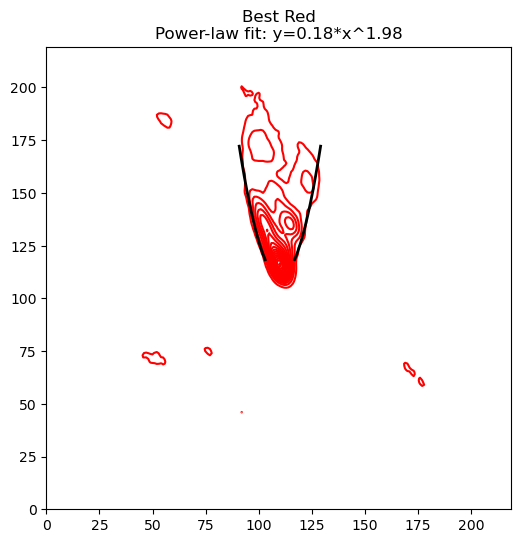

Saved plot data to Per-emb_3_plotdata.pkl


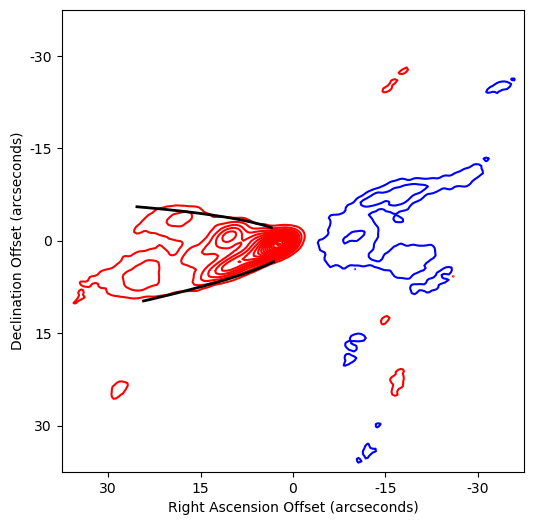

In [ ]:
crossings_RB_combined = combine_red_blue_tracings(red=tilted_tracings_R, blue=tilted_tracings_B,
                                                  center_y=center_y, plot=False, 
                                                  red_ims=tilted_images_R, blue_ims=tilted_images_B,
                                                  image_stats=stats, name='Per-emb 5',
                                                 red_threshold=0.8, blue_threshold=0.8)


Bonus! Use this to make a nice little grid of a bunch of objects from the pickle files you created

Saved combined_outflow_grid.pdf!


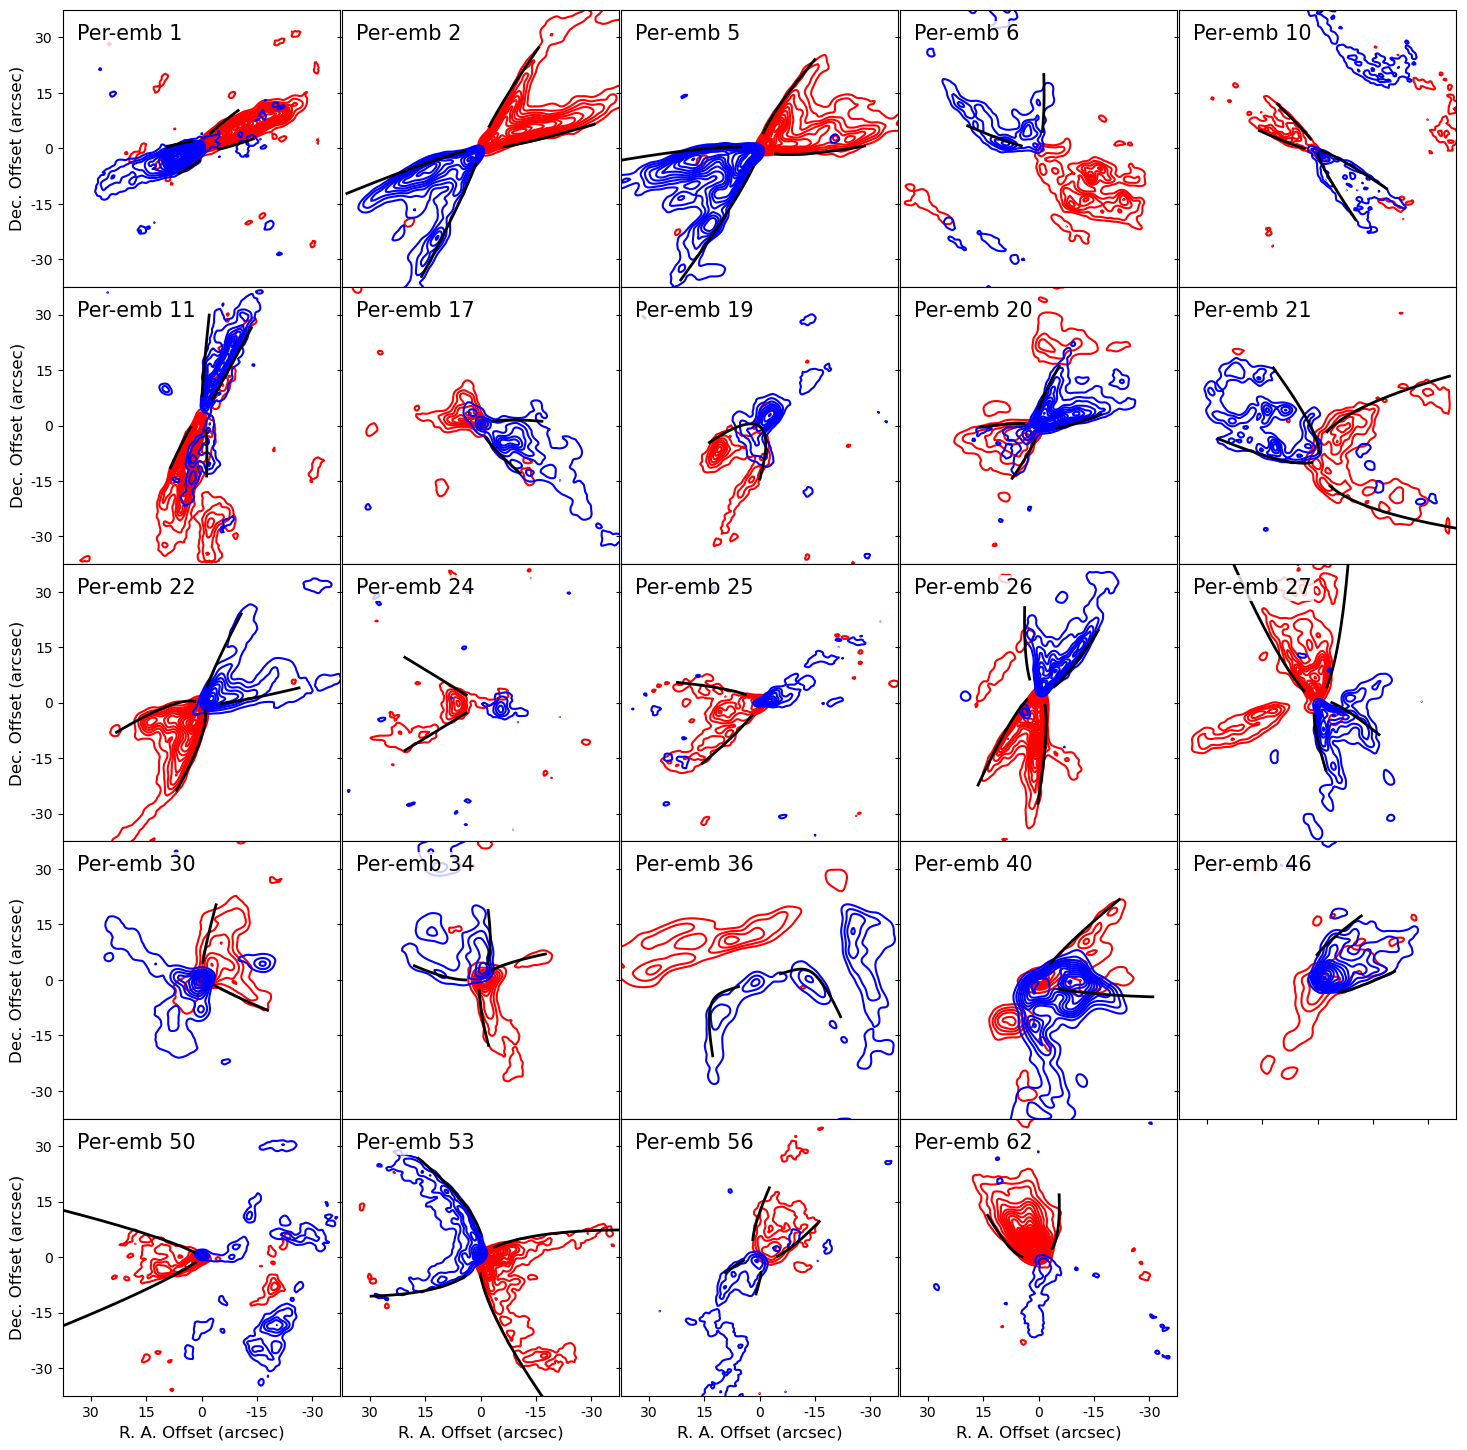

In [361]:

# Run this completely separately after you have generated all the .pkl files

def plot_single_panel_from_data(ax, data):
    """
    Reconstructs a single plot on a specific axis using the saved dictionary.
    """
    # Unpack the saved data
    center_y = data['center_y']
    xr, yr = data['xr'], data['yr']
    xb, yb = data['xb'], data['yb']
    best_angle_r, best_angle_b = data['best_angle_r'], data['best_angle_b']
    pixscale = data['pixscale']
    method = data['method']
    
    if method == "bluetop":
        # Recreate the transforms using the NEW axis (ax.transData)
        transr = Affine2D().rotate_deg_around(center_y, center_y, best_angle_r).translate(xr-center_y, yr-center_y) + ax.transData
        transb = Affine2D().rotate_deg_around(center_y, center_y, best_angle_b).translate(xb-center_y, yb-center_y) + ax.transData

        # ----- RED SIDE -----
        # Plot contour if image exists
        if data.get('image_r') is not None:
            ax.contour(data['image_r'], levels=data['levels_r'], colors='red', transform=transr)


        # ----- BLUE SIDE -----
        # Plot contour if image exists
        if data.get('image_b') is not None:
            ax.contour(data['image_b'], levels=data['levels_b'], colors='blue', transform=transb)

        # Plot curves ONLY if they exist AND are flagged to be included
        if data.get('include_red', True) and data.get('x_curve_r') is not None and data.get('y_curve_r') is not None:
            ax.plot(data['x_curve_r'] + center_y, -data['y_curve_r'] + center_y, color='black', linewidth=2, transform=transr)
            ax.plot(-data['x_curve_r'] + center_y, -data['y_curve_r'] + center_y, color='black', linewidth=2, transform=transr)


        # Plot curves ONLY if they exist AND are flagged to be included
        if data.get('include_blue', True) and data.get('x_curve_b') is not None and data.get('y_curve_b') is not None:
            ax.plot(data['x_curve_b'] + center_y, data['y_curve_b'] + center_y, color='black', linewidth=2, transform=transb)
            ax.plot(-data['x_curve_b'] + center_y, data['y_curve_b'] + center_y, color='black', linewidth=2, transform=transb)
    if method == "redtop":
        # Recreate the transforms using the NEW axis (ax.transData)
        transr = Affine2D().rotate_deg_around(center_y, center_y, best_angle_r).translate(xr-center_y, yr-center_y) + ax.transData
        transb = Affine2D().rotate_deg_around(center_y, center_y, best_angle_b).translate(xb-center_y, yb-center_y) + ax.transData

        # ----- RED SIDE -----
        # Plot contour if image exists
        if data.get('image_r') is not None:
            ax.contour(data['image_r'], levels=data['levels_r'], colors='red', transform=transr)


        # ----- BLUE SIDE -----
        # Plot contour if image exists
        if data.get('image_b') is not None:
            ax.contour(data['image_b'], levels=data['levels_b'], colors='blue', transform=transb)

        # Plot curves ONLY if they exist AND are flagged to be included
        if data.get('include_red', True) and data.get('x_curve_r') is not None and data.get('y_curve_r') is not None:
            ax.plot(data['x_curve_r'] + center_y, data['y_curve_r'] + center_y, color='black', linewidth=2, transform=transr)
            ax.plot(-data['x_curve_r'] + center_y, data['y_curve_r'] + center_y, color='black', linewidth=2, transform=transr)


        # Plot curves ONLY if they exist AND are flagged to be included
        if data.get('include_blue', True) and data.get('x_curve_b') is not None and data.get('y_curve_b') is not None:
            ax.plot(data['x_curve_b'] + center_y, -data['y_curve_b'] + center_y, color='black', linewidth=2, transform=transb)
            ax.plot(-data['x_curve_b'] + center_y, -data['y_curve_b'] + center_y, color='black', linewidth=2, transform=transb)
            
    '''if method == "per21":
        # Recreate the transforms using the NEW axis (ax.transData)
        best_angle_b_phony = best_angle_b-150
        transr = Affine2D().rotate_deg_around(center_y, center_y, best_angle_r).translate(xr-center_y, yr-center_y) + ax.transData
        transb_p = Affine2D().rotate_deg_around(center_y, center_y, best_angle_b_phony).translate(xb-center_y, yb-center_y) + ax.transData
        transb = Affine2D().rotate_deg_around(center_y, center_y, best_angle_b).translate(xb-center_y, yb-center_y) + ax.transData

        # ----- RED SIDE -----
        # Plot contour if image exists
        if data.get('image_r') is not None:
            ax.contour(data['image_r'], levels=data['levels_r'], colors='red', transform=transr)


        # ----- BLUE SIDE -----
        # Plot contour if image exists
        if data.get('image_b') is not None:
            ax.contour(data['image_b'], levels=data['levels_b'], colors='blue', transform=transb_p)

        # Plot curves ONLY if they exist AND are flagged to be included
        if data.get('include_red', True) and data.get('x_curve_r') is not None and data.get('y_curve_r') is not None:
            ax.plot(data['x_curve_r'] + center_y, data['y_curve_r'] + center_y, color='black', linewidth=2, transform=transr)
            ax.plot(-data['x_curve_r'] + center_y, data['y_curve_r'] + center_y, color='black', linewidth=2, transform=transr)


        # Plot curves ONLY if they exist AND are flagged to be included
        # Plot curves ONLY if they exist AND are flagged to be included
        if data.get('include_blue', True) and data.get('x_curve_b') is not None and data.get('y_curve_b') is not None:
            ax.plot(data['x_curve_b'] + center_y, data['y_curve_b'] + center_y, color='black', linewidth=2, transform=transb)
            ax.plot(-data['x_curve_b'] + center_y, data['y_curve_b'] + center_y, color='black', linewidth=2, transform=transb)'''

    # ----- FORMATTING -----
    # Source Name Label inside the plot (top left)
    ax.text(0.05, 0.95, data['source_name'], transform=ax.transAxes, fontsize=15,
            verticalalignment='top', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', pad=2))

    # Axis Limits and Ticks
    def arcsec_to_pix_x(arc):
        return -arc / pixscale + xr

    custom_ticks_arc_x = np.array([30, 15, 0, -15, -30])
    custom_ticks_pix_x = arcsec_to_pix_x(custom_ticks_arc_x)
    
    def arcsec_to_pix_y(arc):
        return arc / pixscale + xr

    custom_ticks_arc_y = np.array([30, 15, 0, -15, -30])
    custom_ticks_pix_y = arcsec_to_pix_y(custom_ticks_arc_y)

    ax.set_xticks(custom_ticks_pix_x)
    ax.set_yticks(custom_ticks_pix_y)

    ax.set_aspect('equal')
    ax.set_xlim(arcsec_to_pix_x(30+7.5), arcsec_to_pix_x(-30-7.5))
    ax.set_ylim(arcsec_to_pix_y(-30-7.5), arcsec_to_pix_y(30+7.5))


def create_final_grid():
    # 1. Find all saved pickle files in the directory
    pickle_files = sorted(glob.glob("*_plotdata.pkl"))
    if not pickle_files:
        print("No .pkl files found! Run your main function first to generate them.")
        return

    # 2. Load all data
    all_sources_data = []
    for pf in pickle_files:
        with open(pf, 'rb') as f:
            all_sources_data.append(pickle.load(f))

    # 3. Setup the Grid (e.g., 4x4 if you have up to 16 sources)
    # Calculate rows/cols needed based on number of files, or hardcode to 4x4
    num_sources = len(all_sources_data)
    cols = 5
    rows = int(np.ceil(num_sources / cols))
    
    # REMOVED sharex=True, sharey=True because pixel centers vary per image!
    fig, axes = plt.subplots(rows, cols, figsize=(18, 18 * (rows/cols)))
    plt.subplots_adjust(wspace=0, hspace=0) # Removes gaps between plots
    
    # Safely flatten axes for easy iteration (handles both single axis and ndarray returns)
    if isinstance(axes, np.ndarray):
        axes_flat = axes.flatten()
    else:
        axes_flat = [axes]

    # 4. Plot each source onto the grid
    for i, data in enumerate(all_sources_data):
        ax = axes_flat[i]
        plot_single_panel_from_data(ax, data)
        
        # Add labels ONLY to the left column and bottom row
        if i % cols == 0: 
            ax.set_ylabel("Dec. Offset (arcsec)", fontsize=12)
            ax.set_yticklabels([str(int(t)) for t in np.array([30, 15, 0, -15, -30])])
        else:
            ax.set_yticklabels([]) # Hide inner y-axis labels
            
        # Check if it's on the bottom row
        if i >= (rows - 1) * cols: 
            ax.set_xlabel("R. A. Offset (arcsec)", fontsize=12)
            ax.set_xticklabels([str(int(t)) for t in np.array([30, 15, 0, -15, -30])])
        else:
            ax.set_xticklabels([]) # Hide inner x-axis labels

    # Turn off unused subplots if your sources don't perfectly fill the grid
    for j in range(num_sources, len(axes_flat)):
        axes_flat[j].axis('off')

    plt.savefig('combined_outflow_grid.pdf', bbox_inches='tight', dpi=300)
    print("Saved combined_outflow_grid.pdf!")
    plt.show()

# If you run this file directly, it will attempt to build the grid
if __name__ == "__main__":
    create_final_grid()